In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path

from sklearn.preprocessing import RobustScaler

This is the historical data that covers sales from 2010-02-05 to 2012-11-01, in the file Walmart_Store_sales. Within this file you will find the following fields:\

Store - the store number
Date - the week of sales
Weekly_Sales - sales for the given store
Holiday_Flag - whether the week is a special holiday week 1 – Holiday week 0 – Non-holiday week
Temperature - Temperature on the day of sale
Fuel_Price - Cost of fuel in the region
CPI – Prevailing consumer price index
Unemployment - Prevailing unemployment rate
Holiday Events<br /> Super Bowl: 12-Feb-10, 11-Feb-11, 10-Feb-12, 8-Feb-13<br /> Labour Day: 10-Sep-10, 9-Sep-11, 7-Sep-12, 6-Sep-13<br /> Thanksgiving: 26-Nov-10, 25-Nov-11, 23-Nov-12, 29-Nov-13<br /> Christmas: 31-Dec-10, 30-Dec-11, 28-Dec-12, 27-Dec-13

In [2]:
OUT_DIR = Path("outdir")
df = pd.read_csv("Walmart.csv")

print("Размер:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing"))
print("Полные дубликаты:", df.duplicated().sum())
print("Число магазинов:", df["Store"].nunique())

Размер: (6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


,dtype
Store,int64
Date,str
Weekly_Sales,float64
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,float64
Unemployment,float64


,missing
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


Полные дубликаты: 0
Число магазинов: 45


Заполнение пропусков:
судя по анализу, данные без пропусков

In [3]:
missing = df.isnull().sum()

print("Количество пропусков по столбцам:")
print(missing)

if missing.sum() == 0:
    print("Пропуски отсутствуют, заполнение не требуется.")

Количество пропусков по столбцам:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64
Пропуски отсутствуют, заполнение не требуется.


Форматирование типов данных

In [4]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
numeric_columns = [
    "Store", "Weekly_Sales", "Holiday_Flag", "Temperature",
    "Fuel_Price", "CPI", "Unemployment",
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

before = len(df)
df = df.drop_duplicates().dropna(subset=["Store", "Date", "Weekly_Sales"]).copy()
print("Удалено дубликатов и строк без ключа/цели:", before - len(df))

predictors = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]
for column in predictors:
    store_median = df.groupby("Store")[column].transform("median")
    df[column] = df[column].fillna(store_median).fillna(df[column].median())

holiday_mode = df["Holiday_Flag"].mode()
df["Holiday_Flag"] = df["Holiday_Flag"].fillna(
    int(holiday_mode.iloc[0]) if not holiday_mode.empty else 0
)
df["Store"] = df["Store"].astype("int16")
df["Holiday_Flag"] = df["Holiday_Flag"].astype("int8")
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

print("Пропусков после форматирования и обработки:", int(df.isna().sum().sum()))
print("Магазинов:", df["Store"].nunique(), "| недель:", df["Date"].nunique())
assert df["Store"].between(1, 45).all()
assert set(df["Holiday_Flag"].unique()).issubset({0, 1})
assert not df.duplicated(["Store", "Date"]).any()
display(df.dtypes.to_frame("Итоговый тип"))


Удалено дубликатов и строк без ключа/цели: 0
Пропусков после форматирования и обработки: 0
Магазинов: 45 | недель: 143


,Итоговый тип
Store,int16
Date,datetime64[us]
Weekly_Sales,float64
Holiday_Flag,int8
Temperature,float64
Fuel_Price,float64
CPI,float64
Unemployment,float64


Удаление выбросов

,Всего IQR-флагов,Ниже границы,Выше границы
Показатель,,,
Weekly_Sales,300,21,279
Temperature,0,0,0
Fuel_Price,0,0,0
CPI,0,0,0
Unemployment,32,8,24


,count,mean,std,min,25%,50%,75%,max
Weekly_Sales,6435.0,1046964.878,564366.622,209986.250,553350.105,960746.040,1420158.660,3818686.450
Temperature,6435.0,60.664,18.445,-2.060,47.460,62.670,74.940,100.140
Fuel_Price,6435.0,3.359,0.459,2.472,2.933,3.445,3.735,4.468
CPI,6435.0,171.578,39.357,126.064,131.735,182.617,212.743,227.233
Unemployment,6435.0,7.999,1.876,3.879,6.891,7.874,8.622,14.313


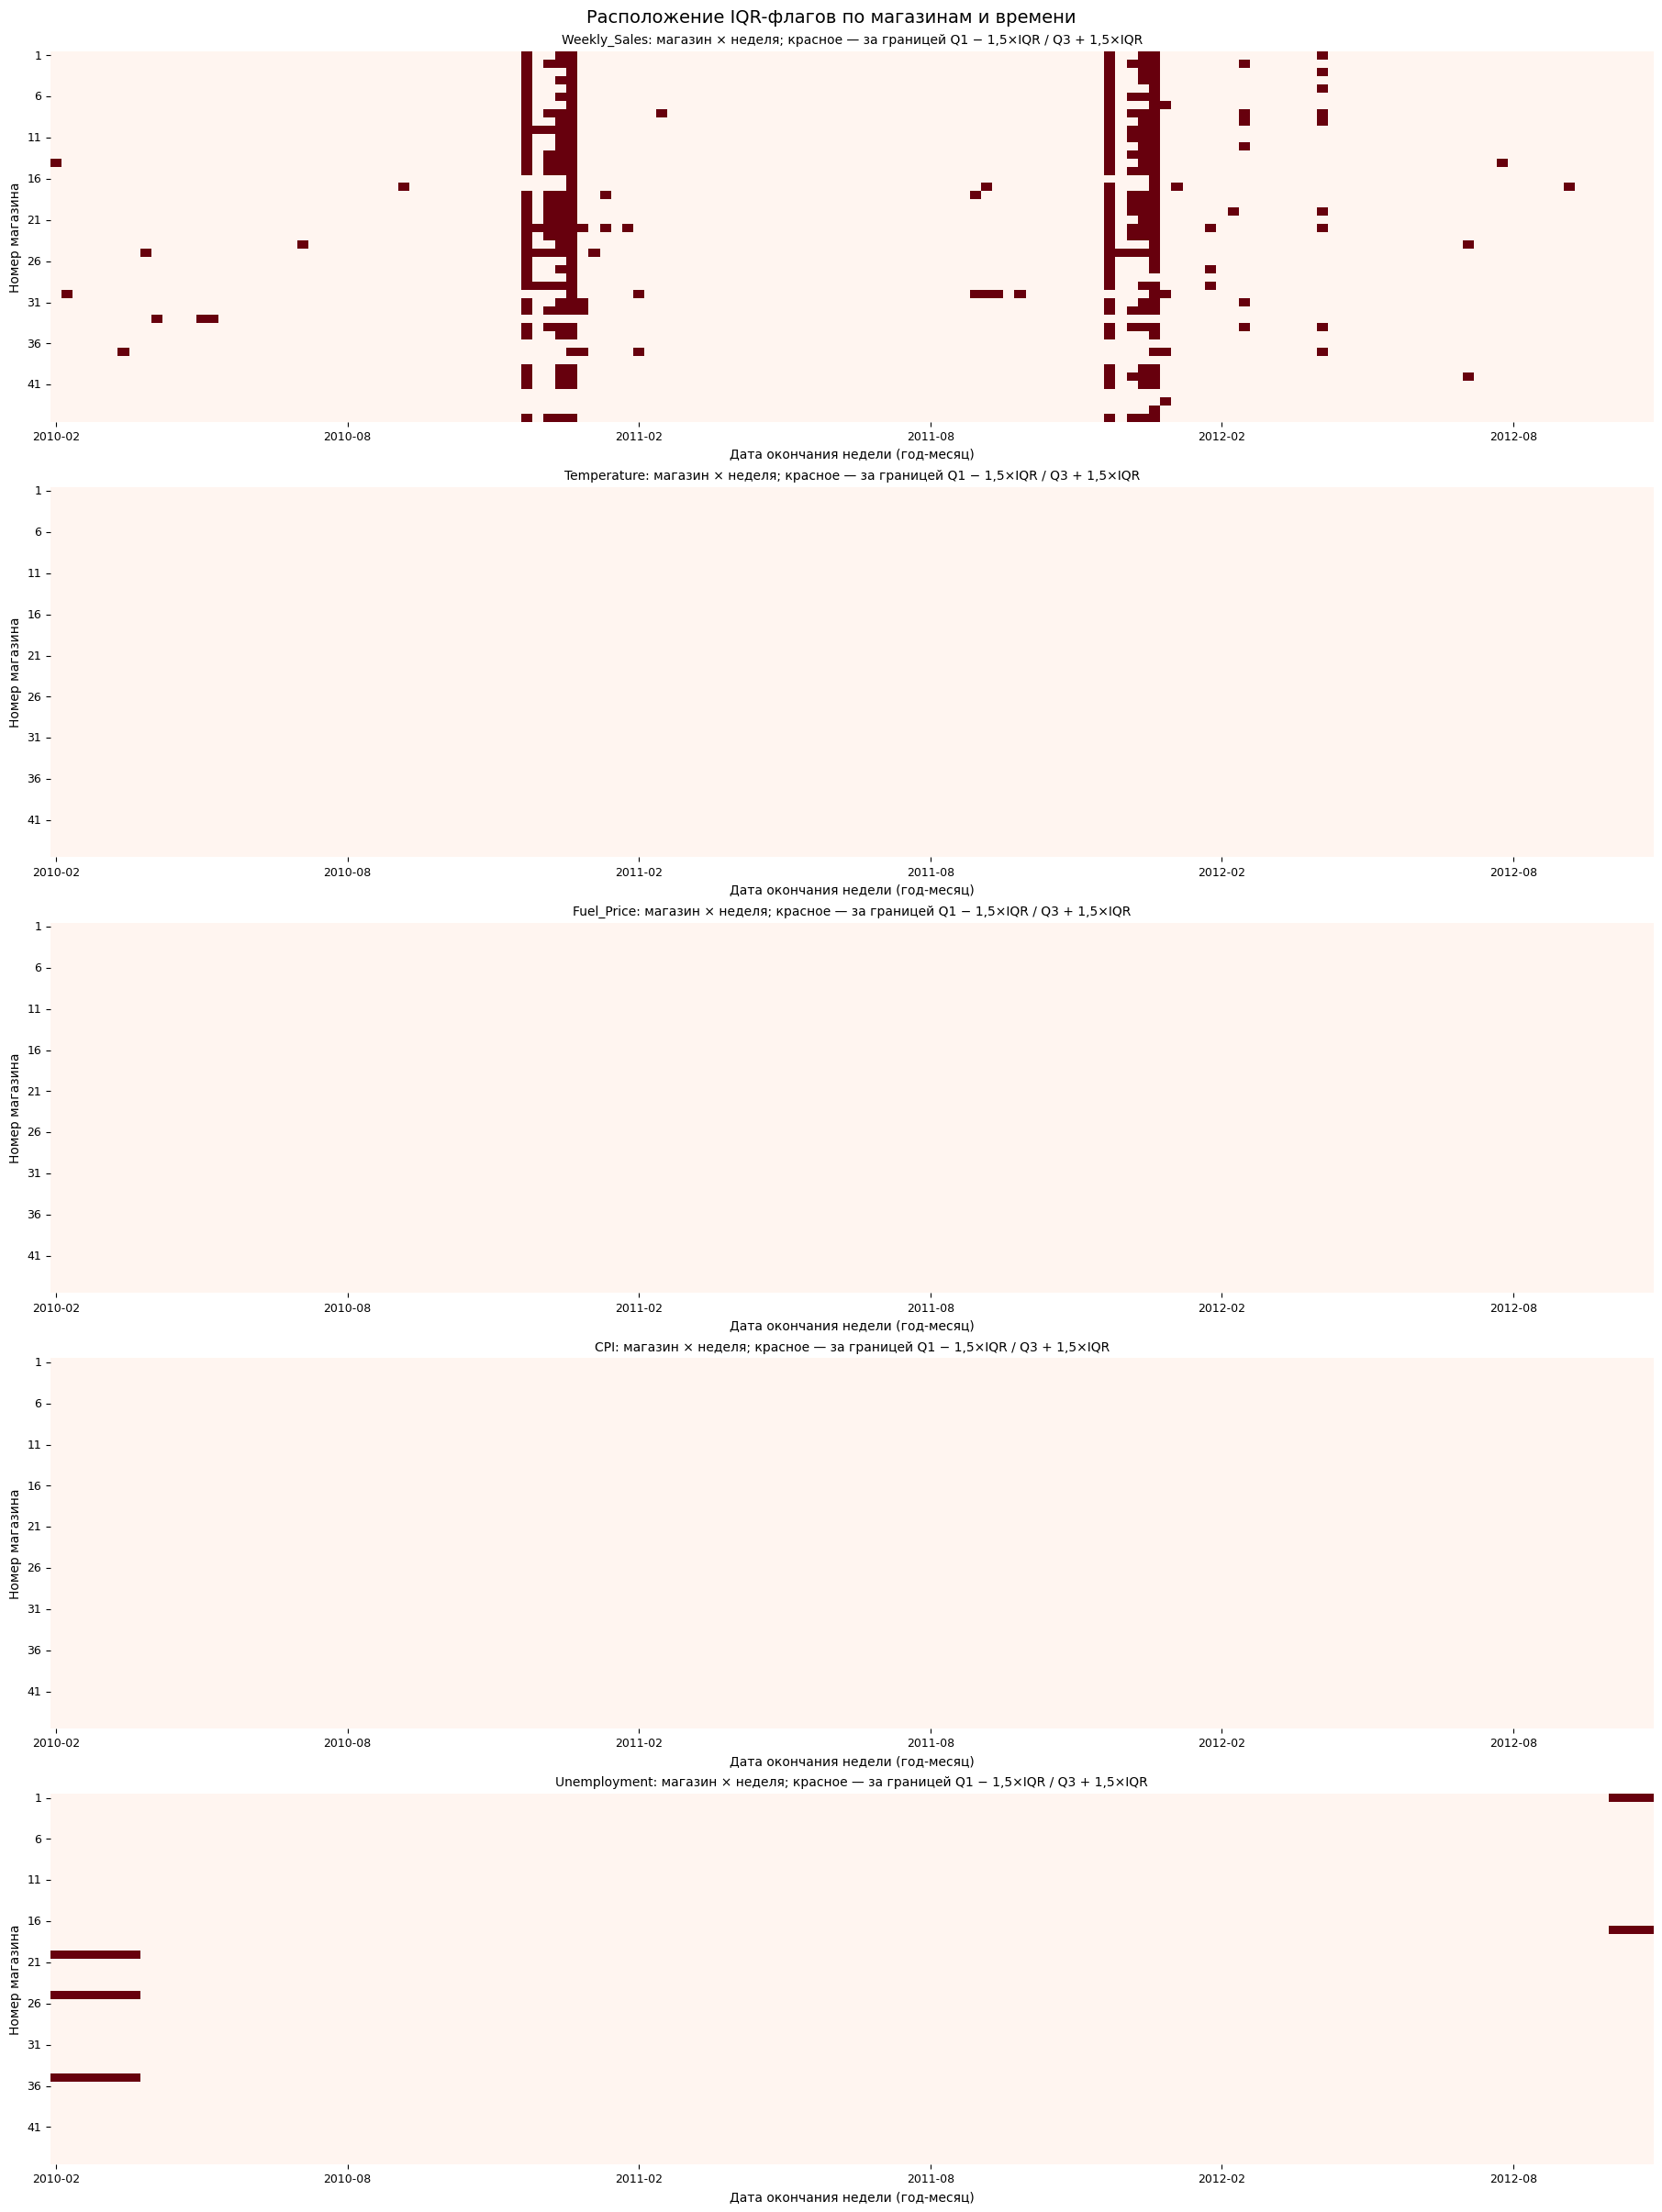

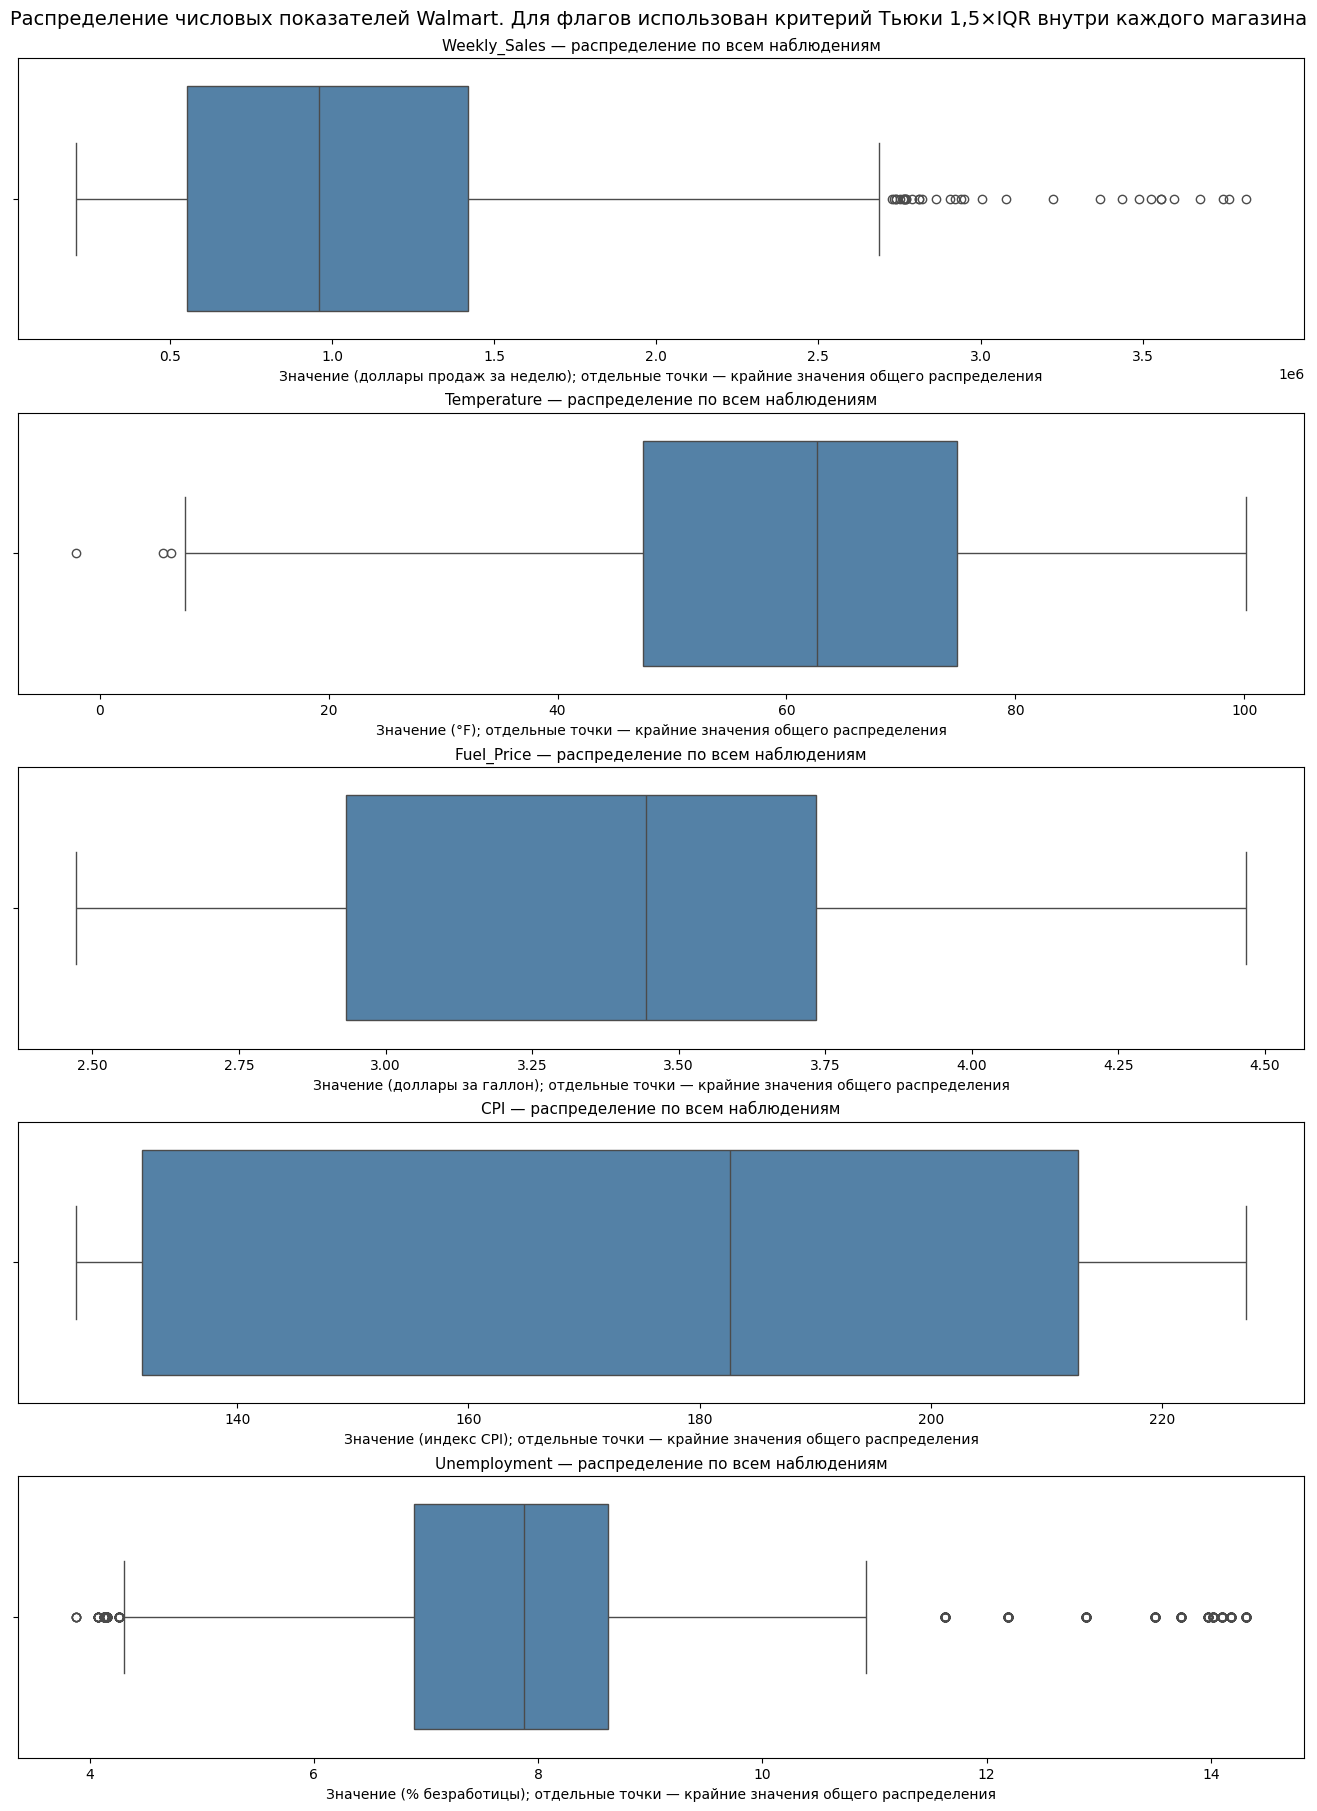

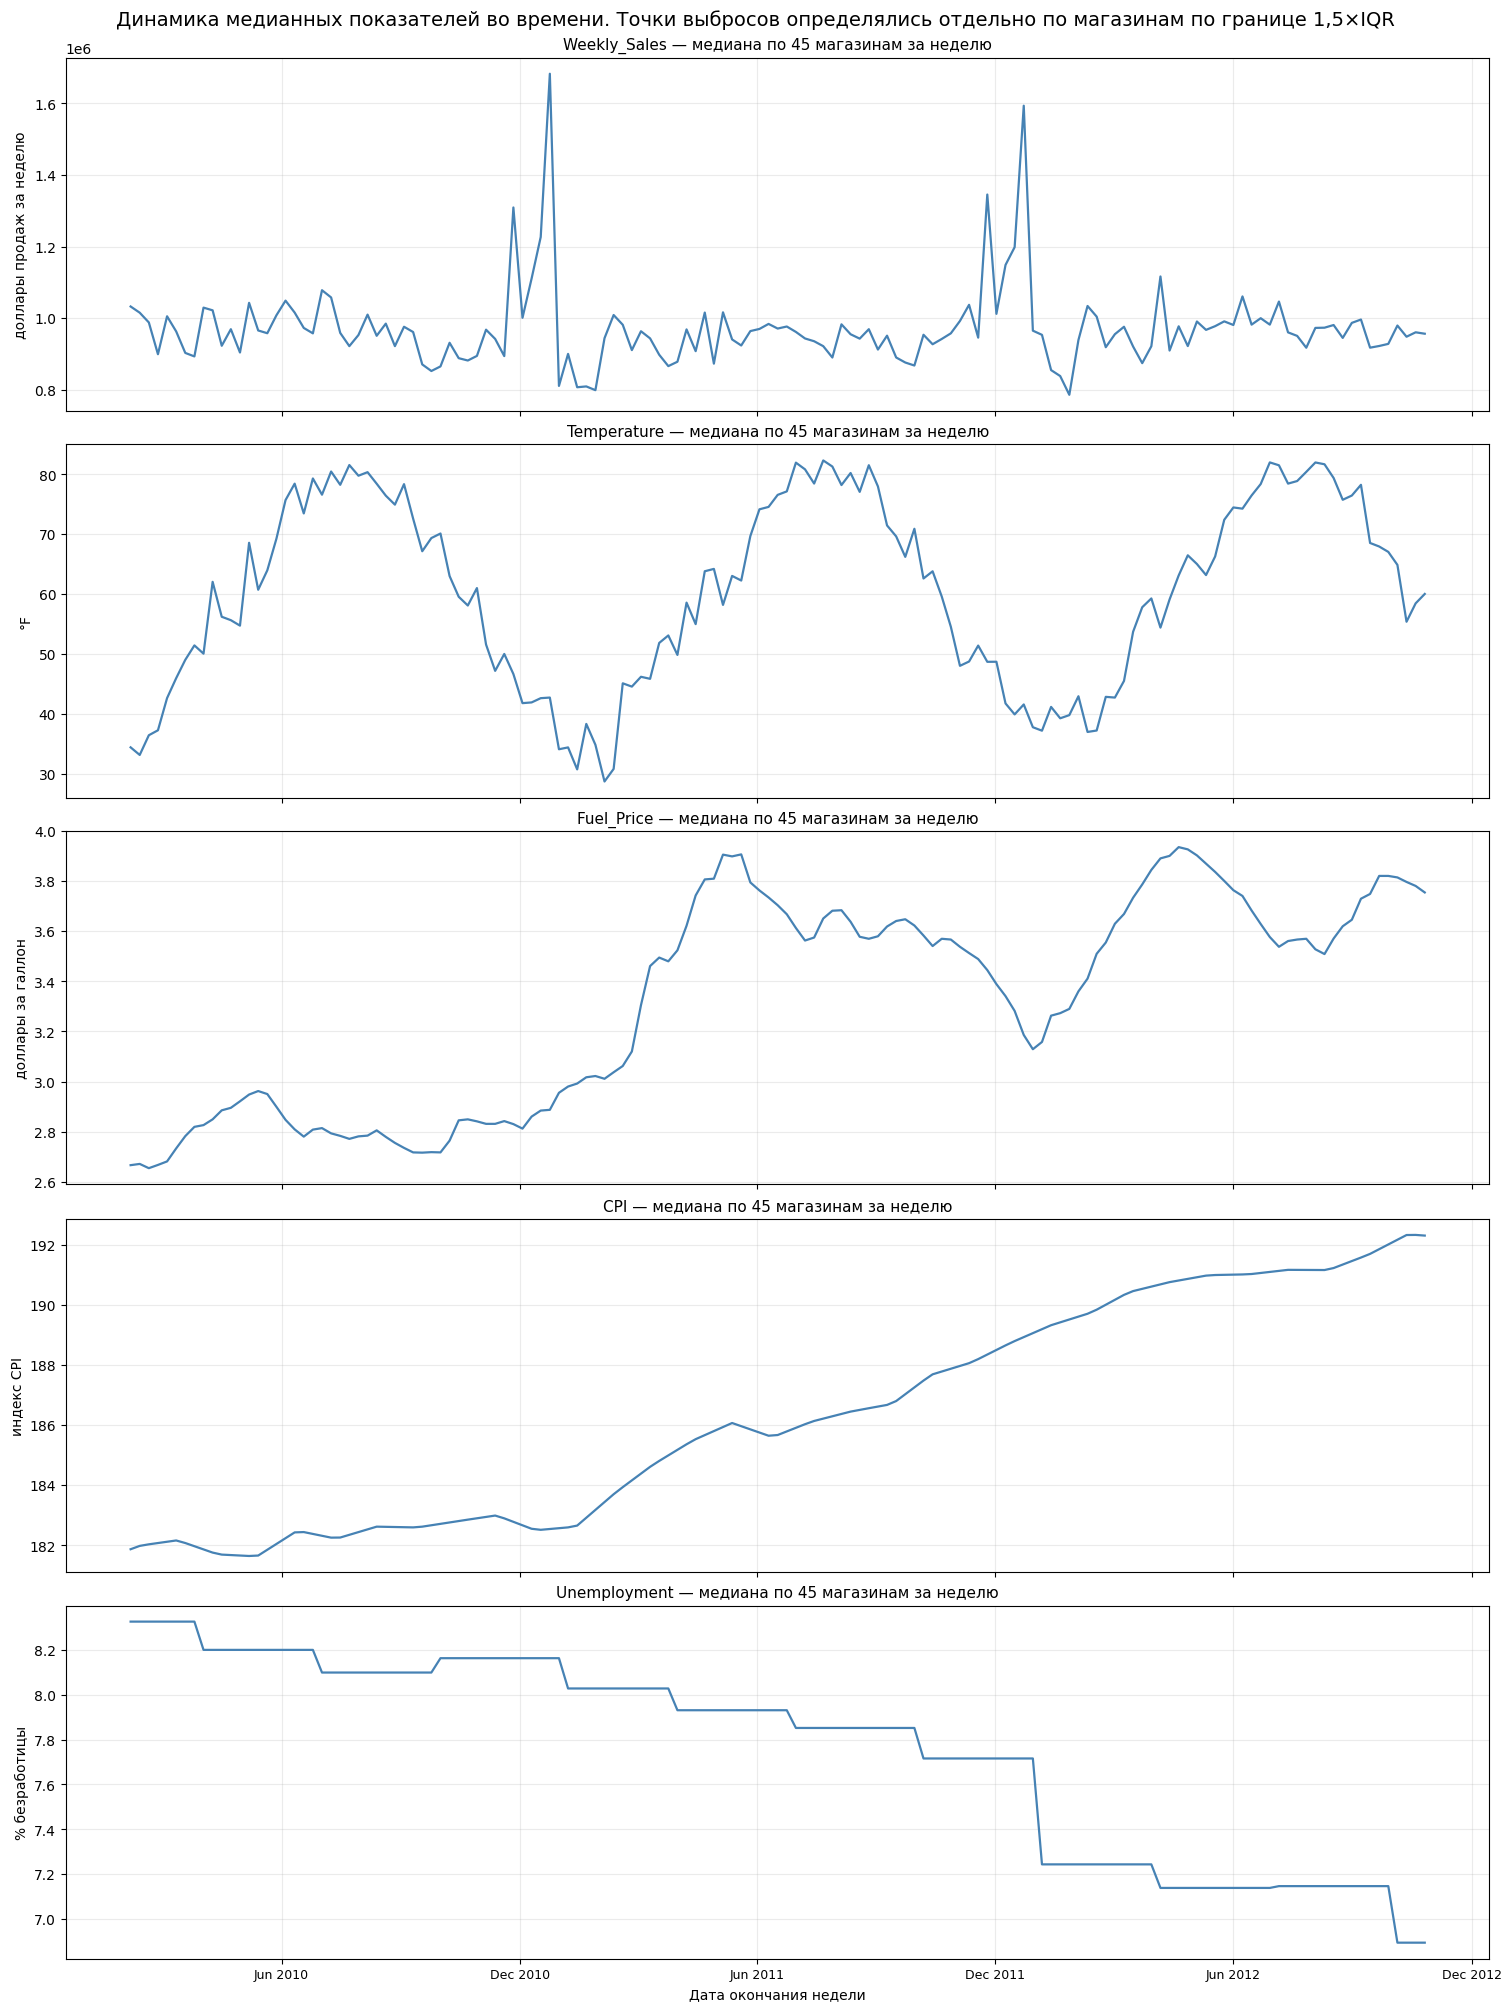

In [5]:
value_columns = ["Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
outlier_summary = []

for column in value_columns:
    by_store = df.groupby("Store")[column]
    q1 = by_store.transform(lambda values: values.quantile(0.25))
    q3 = by_store.transform(lambda values: values.quantile(0.75))
    iqr = q3 - q1
    low = df[column] < (q1 - 1.5 * iqr)
    high = df[column] > (q3 + 1.5 * iqr)
    df[f"Outlier_Low_{column}"] = low
    df[f"Outlier_High_{column}"] = high
    outlier_summary.append({
        "Показатель": column,
        "Всего IQR-флагов": int((low | high).sum()),
        "Ниже границы": int(low.sum()),
        "Выше границы": int(high.sum()),
    })

outlier_summary = pd.DataFrame(outlier_summary).set_index("Показатель")
display(outlier_summary)
display(df[value_columns].describe().T.round(3))

# IQR-флаги посчитаны отдельно внутри каждого магазина по границам Тьюки:
# ниже Q1 - 1.5*IQR или выше Q3 + 1.5*IQR.
fig, axes = plt.subplots(len(value_columns), 1, figsize=(18, 24), constrained_layout=True)
for ax, column in zip(axes, value_columns):
    flag = df[f"Outlier_Low_{column}"] | df[f"Outlier_High_{column}"]
    matrix = df.assign(_flag=flag).pivot(index="Store", columns="Date", values="_flag").astype(int)
    sns.heatmap(matrix, cmap="Reds", vmin=0, vmax=1, cbar=False, ax=ax)

    date_positions = np.arange(0, len(matrix.columns), 26)
    ax.set_xticks(date_positions + 0.5)
    ax.set_xticklabels(
        [matrix.columns[i].strftime("%Y-%m") for i in date_positions],
        rotation=0, fontsize=9,
    )
    store_positions = np.arange(0, len(matrix.index), 5)
    ax.set_yticks(store_positions + 0.5)
    ax.set_yticklabels(matrix.index[store_positions], rotation=0, fontsize=9)
    ax.set_title(
        f"{column}: магазин × неделя; красное — за границей Q1 − 1,5×IQR / Q3 + 1,5×IQR",
        fontsize=10, pad=6,
    )
    ax.set_xlabel("Дата окончания недели (год-месяц)")
    ax.set_ylabel("Номер магазина")
fig.suptitle("Расположение IQR-флагов по магазинам и времени", fontsize=14)
plt.show()

# Boxplots показывают общий диапазон значений; IQR-флаги выше рассчитаны отдельно по магазинам.
units = {
    "Weekly_Sales": "доллары продаж за неделю",
    "Temperature": "°F",
    "Fuel_Price": "доллары за галлон",
    "CPI": "индекс CPI",
    "Unemployment": "% безработицы",
}
fig, axes = plt.subplots(len(value_columns), 1, figsize=(13, 18), constrained_layout=True)
for ax, column in zip(axes, value_columns):
    sns.boxplot(x=df[column], ax=ax, color="steelblue", showfliers=True)
    ax.set_title(f"{column} — распределение по всем наблюдениям", fontsize=11)
    ax.set_xlabel(f"Значение ({units[column]}); отдельные точки — крайние значения общего распределения")
    ax.set_ylabel("")
fig.suptitle(
    "Распределение числовых показателей Walmart. Для флагов использован критерий Тьюки 1,5×IQR внутри каждого магазина",
    fontsize=14,
)
plt.show()

weekly_medians = df.groupby("Date")[value_columns].median()
fig, axes = plt.subplots(len(value_columns), 1, figsize=(15, 20), sharex=True, constrained_layout=True)
for ax, column in zip(axes, value_columns):
    ax.plot(weekly_medians.index, weekly_medians[column], color="steelblue", linewidth=1.6)
    ax.set_title(f"{column} — медиана по 45 магазинам за неделю", fontsize=11)
    ax.set_ylabel(units[column])
    ax.grid(True, alpha=0.25)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", labelrotation=0, labelsize=9)
axes[-1].set_xlabel("Дата окончания недели")
fig.suptitle(
    "Динамика медианных показателей во времени. Точки выбросов определялись отдельно по магазинам по границе 1,5×IQR",
    fontsize=14,
)
plt.show()


сопоставление с показателями сша

In [6]:
# Диапазоны национальных рядов США в период 2010–2012 гг.
us_ranges = {
    "CPI": (217.281, 231.638),
    "Unemployment": (7.8, 9.9),
    "Fuel_Price": (2.709, 3.982),
}
comparison = []
for column, (us_min, us_max) in us_ranges.items():
    walmart_mean = df[column].mean()
    comparison.append({
        "Показатель": column,
        "Среднее Walmart за период": walmart_mean,
        "Диапазон США — от": us_min,
        "Диапазон США — до": us_max,
        "Среднее Walmart входит в диапазон США": us_min <= walmart_mean <= us_max,
    })
comparison = pd.DataFrame(comparison).set_index("Показатель")
display(comparison.round(3))


,Среднее Walmart за период,Диапазон США — от,Диапазон США — до,Среднее Walmart входит в диапазон США
Показатель,,,,
CPI,171.578,217.281,231.638,False
Unemployment,7.999,7.800,9.900,True
Fuel_Price,3.359,2.709,3.982,True


Праздники

Исходных праздничных недель: 10
Праздничные даты без совпадения с четырьмя событиями: []


,Holiday,Holiday_Date,Week_Ending
0,New Year,2010-01-01,2010-01-01
6,Super Bowl,2010-02-07,2010-02-12
3,Valentine's Day,2010-02-14,2010-02-19
9,Easter,2010-04-04,2010-04-09
12,Mother's Day,2010-05-09,2010-05-14
15,Memorial Day,2010-05-31,2010-06-04
18,Father's Day,2010-06-20,2010-06-25
21,Independence Day,2010-07-04,2010-07-09
24,Labor Day,2010-09-06,2010-09-10
27,Halloween,2010-10-31,2010-11-05


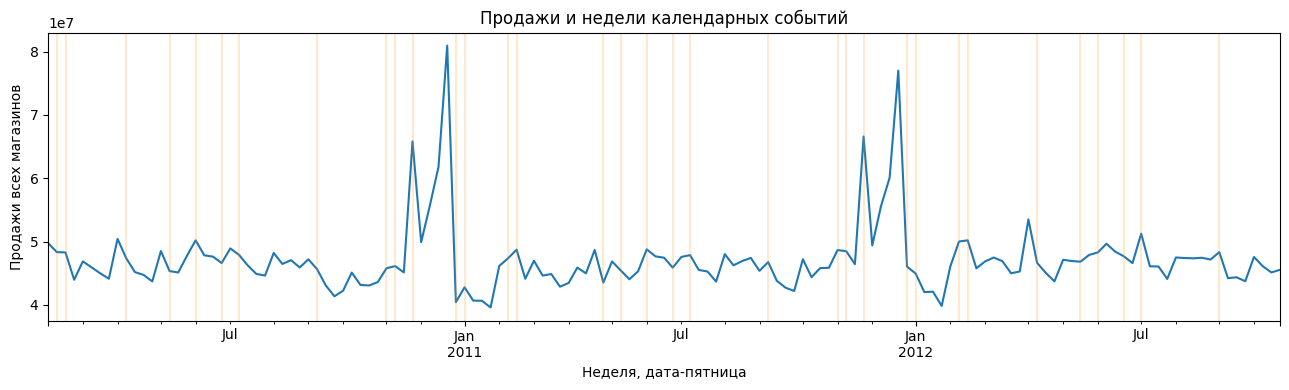

In [7]:
holiday_dates = {
    "New Year": ["2010-01-01", "2011-01-01", "2012-01-01"],
    "Valentine's Day": ["2010-02-14", "2011-02-14", "2012-02-14"],
    "Super Bowl": ["2010-02-07", "2011-02-06", "2012-02-05"],
    "Easter": ["2010-04-04", "2011-04-24", "2012-04-08"],
    "Mother's Day": ["2010-05-09", "2011-05-08", "2012-05-13"],
    "Memorial Day": ["2010-05-31", "2011-05-30", "2012-05-28"],
    "Father's Day": ["2010-06-20", "2011-06-19", "2012-06-17"],
    "Independence Day": ["2010-07-04", "2011-07-04", "2012-07-04"],
    "Labor Day": ["2010-09-06", "2011-09-05", "2012-09-03"],
    "Halloween": ["2010-10-31", "2011-10-31", "2012-10-31"],
    "Veterans Day": ["2010-11-11", "2011-11-11", "2012-11-11"],
    "Thanksgiving": ["2010-11-25", "2011-11-24", "2012-11-22"],
    "Black Friday": ["2010-11-26", "2011-11-25", "2012-11-23"],
    "Christmas": ["2010-12-25", "2011-12-25", "2012-12-25"],
}

event_rows = []
for holiday, dates in holiday_dates.items():
    for date in dates:
        holiday_date = pd.Timestamp(date)
        days_to_friday = (4 - holiday_date.weekday()) % 7
        event_rows.append({
            "Holiday": holiday,
            "Holiday_Date": holiday_date,
            "Week_Ending": holiday_date + pd.Timedelta(days=days_to_friday),
        })
events = pd.DataFrame(event_rows)
events_by_week = events.groupby("Week_Ending")["Holiday"].agg(
    lambda names: ", ".join(sorted(set(names)))
)

df_check = df.copy()
df_check["Holiday_Events"] = df_check["Date"].map(events_by_week).fillna("")
for holiday in holiday_dates:
    column = "Holiday_" + holiday.replace("'", "").replace(" ", "_")
    event_weeks = events.loc[events["Holiday"] == holiday, "Week_Ending"]
    df_check[column] = df_check["Date"].isin(event_weeks).astype("int8")

# Находим ближайшую фактическую дату праздника; знак показывает до/после.
nearest_distance = pd.Series(np.inf, index=df_check.index)
days_from_holiday = pd.Series(np.nan, index=df_check.index)
nearest_holiday = pd.Series("", index=df_check.index, dtype="object")
for _, event in events.iterrows():
    delta = (df_check["Date"] - event["Holiday_Date"]).dt.days
    closer = delta.abs() < nearest_distance
    nearest_distance.loc[closer] = delta.loc[closer].abs()
    days_from_holiday.loc[closer] = delta.loc[closer]
    nearest_holiday.loc[closer] = event["Holiday"]
df_check["Nearest_Holiday"] = nearest_holiday
df_check["Days_From_Nearest_Holiday"] = days_from_holiday
df_check["Holiday_Window_14d"] = nearest_distance.le(14).astype("int8")

# Точные пятницы праздничных недель отдельно сверяем с исходным Holiday_Flag.
big_four = ["Super Bowl", "Labor Day", "Thanksgiving", "Christmas"]
expected_weeks = set(events.loc[events["Holiday"].isin(big_four), "Week_Ending"])
flagged_weeks = set(df_check.loc[df_check["Holiday_Flag"] == 1, "Date"].unique())
print("Исходных праздничных недель:", len(flagged_weeks))
print("Праздничные даты без совпадения с четырьмя событиями:", sorted(flagged_weeks - expected_weeks))
display(events.sort_values("Holiday_Date"))

weekly_sales = df_check.groupby("Date")["Weekly_Sales"].sum()
ax = weekly_sales.plot(figsize=(13, 4), title="Продажи и недели календарных событий")
for week_ending in events["Week_Ending"].unique():
    if week_ending in weekly_sales.index:
        ax.axvline(week_ending, color="darkorange", alpha=0.2)
ax.set_xlabel("Неделя, дата-пятница")
ax.set_ylabel("Продажи всех магазинов")
plt.tight_layout()
plt.show()


Всего IQR-флагов продаж: 300
В окне +-14 дней до/после праздника, оставлены: 297
Удаляемые продажные флаги вне окна: 3


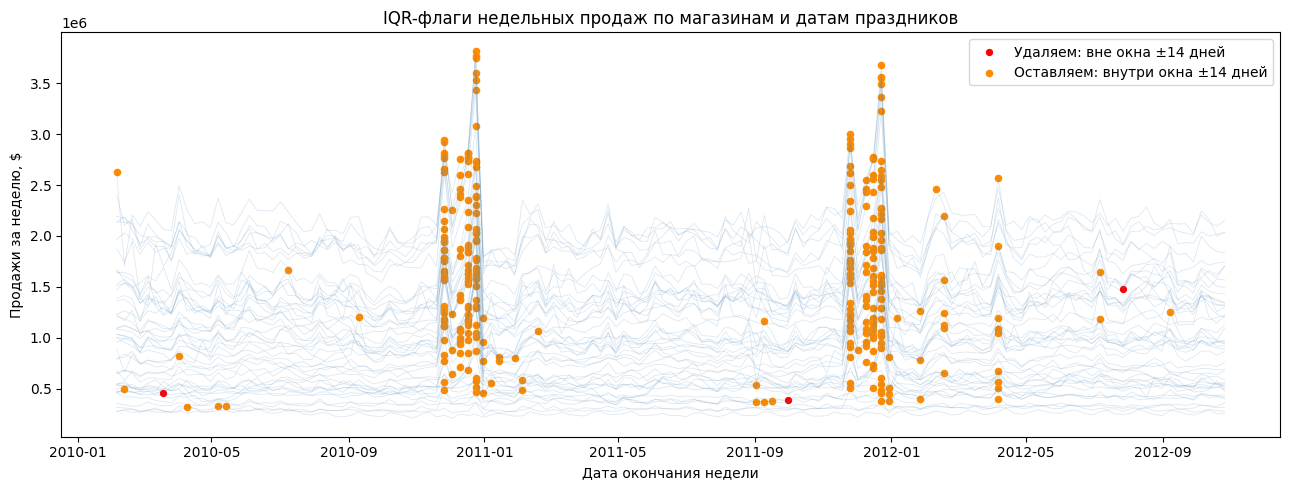

In [8]:
sales_outlier = (
    df_check["Outlier_Low_Weekly_Sales"] | df_check["Outlier_High_Weekly_Sales"]
)
df_check["Holiday_Peak"] = sales_outlier & df_check["Holiday_Window_14d"].eq(1)
df_check["Confirmed_IQR_Outlier"] = sales_outlier & ~df_check["Holiday_Peak"]
df_check["Remove_Sales_Outlier"] = df_check["Confirmed_IQR_Outlier"]

print("Всего IQR-флагов продаж:", int(sales_outlier.sum()))
print("В окне +-14 дней до/после праздника, оставлены:", int(df_check["Holiday_Peak"].sum()))
print("Удаляемые продажные флаги вне окна:", int(df_check["Remove_Sales_Outlier"].sum()))


fig, ax = plt.subplots(figsize=(13, 5))
for _, group in df_check.groupby("Store"):
    ax.plot(group["Date"], group["Weekly_Sales"], linewidth=0.6, alpha=0.18, color="steelblue")
ordinary = df_check[df_check["Confirmed_IQR_Outlier"]]
holiday_peaks = df_check[df_check["Holiday_Peak"]]
ax.scatter(ordinary["Date"], ordinary["Weekly_Sales"], color="red", s=18, label="Удаляем: вне окна ±14 дней")
ax.scatter(holiday_peaks["Date"], holiday_peaks["Weekly_Sales"], color="darkorange", s=20, label="Оставляем: внутри окна ±14 дней")
ax.set(title="IQR-флаги недельных продаж по магазинам и датам праздников", xlabel="Дата окончания недели", ylabel="Продажи за неделю, $")
ax.legend()
plt.tight_layout()
plt.show()

df_clean = df_check.copy()


Проектирование признаков и лаггирование

In [9]:
# Календарные признаки
df_clean["Year"] = df_clean["Date"].dt.year.astype("int16")
df_clean["Quarter"] = df_clean["Date"].dt.quarter.astype("int8")
quarter = df_clean["Date"].dt.quarter
df_clean["Quarter_Sin"] = np.sin(2 * np.pi * quarter / 4)
df_clean["Quarter_Cos"] = np.cos(2 * np.pi * quarter / 4)
month = df_clean["Date"].dt.month
df_clean["Month_Sin"] = np.sin(2 * np.pi * month / 12)
df_clean["Month_Cos"] = np.cos(2 * np.pi * month / 12)
iso = df_clean["Date"].dt.isocalendar()
week = iso.week.astype(float)
weeks_per_year = iso.year.map(
    lambda year: pd.Timestamp(year=int(year), month=12, day=28).isocalendar().week
).astype(float)
df_clean["WeekOfYear_Sin"] = np.sin(2 * np.pi * week / weeks_per_year)
df_clean["WeekOfYear_Cos"] = np.cos(2 * np.pi * week / weeks_per_year)

# Лаги и статистики только по прошлым неделям магазина.
df_clean = df_clean.sort_values(["Store", "Date"]).reset_index(drop=True)
sales_by_store = df_clean.groupby("Store")["Weekly_Sales"]
for lag in [1, 2, 4, 13]:
    df_clean[f"Sales_Lag_{lag}"] = sales_by_store.shift(lag)
for window in [4, 13]:
    df_clean[f"Sales_Roll_Mean_{window}"] = sales_by_store.transform(
        lambda values: values.shift(1).rolling(window, min_periods=window).mean()
    )
    df_clean[f"Sales_Roll_Std_{window}"] = sales_by_store.transform(
        lambda values: values.shift(1).rolling(window, min_periods=window).std()
    )
df_clean["Sales_Expanding_Mean"] = sales_by_store.transform(
    lambda values: values.shift(1).expanding(min_periods=1).mean()
)
df_clean["Lag1_to_RollMean4"] = (
    df_clean["Sales_Lag_1"] / (df_clean["Sales_Roll_Mean_4"].abs() + 1e-6)
)

history_columns = [
    column for column in df_clean.columns
    if column.startswith("Sales_Lag_") or column.startswith("Sales_Roll_")
]
history_columns += ["Sales_Expanding_Mean", "Lag1_to_RollMean4"]
display(df_clean[["Store", "Date", "Weekly_Sales"] + history_columns].head(10))


,Store,Date,Weekly_Sales,Sales_Lag_1,Sales_Lag_2,Sales_Lag_4,Sales_Lag_13,Sales_Roll_Mean_4,Sales_Roll_Std_4,Sales_Roll_Mean_13,Sales_Roll_Std_13,Sales_Expanding_Mean,Lag1_to_RollMean4
0,1,2010-02-05,1643690.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2010-02-12,1641957.44,1643690.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.643691e+06,NaN
2,1,2010-02-19,1611968.17,1641957.44,1643690.90,NaN,NaN,NaN,NaN,NaN,NaN,1.642824e+06,NaN
3,1,2010-02-26,1409727.59,1611968.17,1641957.44,NaN,NaN,NaN,NaN,NaN,NaN,1.632539e+06,NaN
4,1,2010-03-05,1554806.68,1409727.59,1611968.17,1643690.90,NaN,1.576836e+06,112353.415114,NaN,NaN,1.576836e+06,0.894023
5,1,2010-03-12,1439541.59,1554806.68,1409727.59,1641957.44,NaN,1.554615e+06,103135.002548,NaN,NaN,1.572430e+06,1.000123
6,1,2010-03-19,1472515.79,1439541.59,1554806.68,1611968.17,NaN,1.504011e+06,95360.050839,NaN,NaN,1.550282e+06,0.957135
7,1,2010-03-26,1404429.92,1472515.79,1439541.59,1409727.59,NaN,1.469148e+06,62599.457150,NaN,NaN,1.539173e+06,1.002292
8,1,2010-04-02,1594968.28,1404429.92,1472515.79,1554806.68,NaN,1.467823e+06,64308.381016,NaN,NaN,1.522330e+06,0.956811
9,1,2010-04-09,1545418.53,1594968.28,1404429.92,1439541.59,NaN,1.477864e+06,82871.762296,NaN,NaN,1.530401e+06,1.079239


Очистка строк, кодирование категорий

In [10]:
rows_before = len(df_clean)
df_model = df_clean.loc[~df_clean["Remove_Sales_Outlier"]].dropna(
    subset=history_columns
).copy()

technical_columns = [
    column for column in df_model.columns
    if column.startswith("Outlier_")
]
drop_columns = technical_columns + [
    "Holiday_Events", "Next_Event", "Days_Before_Next_Event",
    "Nearest_Holiday", "Days_From_Nearest_Holiday", "Holiday_Window_14d",
    "Holiday_Peak", "Confirmed_IQR_Outlier", "Remove_Sales_Outlier",
]
model_data = df_model.drop(columns=drop_columns, errors="ignore")
model_data = pd.get_dummies(
    model_data, columns=["Store", "Quarter"], dtype="int8"
)

print("Строк до формирования модели:", rows_before)
print("Строк после удаления выбросов и прогрева лагов:", len(model_data))
print("Число признаков с целевой переменной и датой:", len(model_data.columns))
print("Текстовые поля кроме даты:", model_data.drop(columns=["Date"]).select_dtypes(exclude="number").columns.tolist())

assert model_data.drop(columns=["Date"]).select_dtypes(exclude="number").empty
assert model_data.isna().sum().sum() == 0
assert model_data.filter(regex=r"^Store_").sum(axis=1).eq(1).all()
assert model_data.filter(regex=r"^Quarter_[1-4]$").sum(axis=1).eq(1).all()
display(model_data.head())


Строк до формирования модели: 6435
Строк после удаления выбросов и прогрева лагов: 5848
Число признаков с целевой переменной и датой: 87
Текстовые поля кроме даты: []


,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Holiday_New_Year,Holiday_Valentines_Day,Holiday_Super_Bowl,...,Store_40,Store_41,Store_42,Store_43,Store_44,Store_45,Quarter_1,Quarter_2,Quarter_3,Quarter_4
13,2010-05-07,1603955.12,0,72.55,2.835,210.339968,7.808,0,0,0,...,0,0,0,0,0,0,0,1,0,0
14,2010-05-14,1494251.50,0,74.78,2.854,210.337426,7.808,0,0,0,...,0,0,0,0,0,0,0,1,0,0
15,2010-05-21,1399662.07,0,76.44,2.826,210.617093,7.808,0,0,0,...,0,0,0,0,0,0,0,1,0,0
16,2010-05-28,1432069.95,0,80.44,2.759,210.896761,7.808,0,0,0,...,0,0,0,0,0,0,0,1,0,0
17,2010-06-04,1615524.71,0,80.69,2.705,211.176428,7.808,0,0,0,...,0,0,0,0,0,0,0,1,0,0


Масштабирование числовых признаков

In [11]:
excluded = {"Date", "Weekly_Sales", "Year"}
numeric_features = [
    column for column in model_data.select_dtypes(include="number").columns
    if column not in excluded
]
binary_features = [
    column for column in numeric_features
    if set(model_data[column].dropna().unique()).issubset({0, 1})
]
scale_columns = [
    column for column in numeric_features
    if column not in binary_features and not column.endswith(("_Sin", "_Cos"))
]

scaler = RobustScaler()
scaled_data = model_data.copy()
scaled_data[scale_columns] = scaler.fit_transform(model_data[scale_columns])
print("Масштабировано числовых признаков:", len(scale_columns))
print("Масштабированные поля:", scale_columns)
print("Пропусков после масштабирования:", int(scaled_data.isna().sum().sum()))


Масштабировано числовых признаков: 14
Масштабированные поля: ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Sales_Lag_1', 'Sales_Lag_2', 'Sales_Lag_4', 'Sales_Lag_13', 'Sales_Roll_Mean_4', 'Sales_Roll_Std_4', 'Sales_Roll_Mean_13', 'Sales_Roll_Std_13', 'Sales_Expanding_Mean', 'Lag1_to_RollMean4']
Пропусков после масштабирования: 0


Проверка и сохранение

In [12]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert scaled_data.isna().sum().sum() == 0
assert list(model_data.columns) == list(scaled_data.columns)
assert model_data["Date"].notna().all()
assert "Weekly_Sales" in model_data.columns
assert not (set(model_data.columns) & {"Holiday_Events", "Next_Event"})

prepared_path = OUT_DIR / "walmart_prepared.csv"
scaled_path = OUT_DIR / "walmart_scaled.csv"

model_data.to_csv(prepared_path, index=False)
scaled_data.to_csv(scaled_path, index=False)

print("Подготовленные данные:", prepared_path.resolve(), model_data.shape)
print("Масштабированная версия:", scaled_path.resolve(), scaled_data.shape)

Подготовленные данные: C:\ITMO\основы анализа данных\lab1\outdir\walmart_prepared.csv (5848, 87)
Масштабированная версия: C:\ITMO\основы анализа данных\lab1\outdir\walmart_scaled.csv (5848, 87)
